# Step 1: Project Planning & Problem Framing

### 1. What is Data Analysis?
Data Analysis is the systematic process of inspecting, cleaning, transforming, and modeling raw data with the goal of discovering useful information, drawing conclusions, and supporting decision-making in a business context.

### 2. Steps in a Data Science Project Lifecycle
A typical data science and machine learning project follows these sequential phases:
* **Business Understanding & Problem Framing:** Defining what we want to predict and why it matters.
* **Data Collection & Integration:** Pulling data from various sources (CSV, JSON, SQL, APIs).
* **Exploratory Data Analysis (EDA):** Uncovering patterns, missing values, anomalies, and correlations.
* **Data Preprocessing & Cleaning:** Handling missing data, outliers, mixed variables, and data types.
* **Feature Engineering & Transformation:** Creating new variables, encoding categorical features, scaling numeric features.
* **Model Building & Evaluation:** Training ML models and evaluating their performance.
* **Deployment & Monitoring:** Putting the model into production.

### 3. Framing as a Machine Learning Problem (Binary Classification)
* **Goal:** Predict whether a customer will make a purchase or not based on their demographics, transaction history, and product details.
* **Target Variable:** `purchased` (Categorical column).
* **Classification Type:** **Binary Classification** because the target has only two possible discrete outcomes:
  * `1` $\rightarrow$ The customer made a purchase.
  * `0` $\rightarrow$ The customer did not make a purchase.

In [2]:
# Step 1 Verification: Confirming the Problem Setup
print("Project: Customer Purchase Propensity Pipeline")
print("Problem Type: Binary Classification")
print("Target Variable: 'purchased' (Values: 0 or 1)")

Project: Customer Purchase Propensity Pipeline
Problem Type: Binary Classification
Target Variable: 'purchased' (Values: 0 or 1)


# Step 2: Data Import and Understanding

In [3]:
import sqlite3
import json
import pandas as pd
import numpy as np
import requests

# 1. Create Synthetic Raw Files (If not already present locally)
customers_data = pd.DataFrame({
    'customer_id': ['CUST_101', 'CUST_102', 'CUST_103', 'CUST_104', 'CUST_105', 
                    'CUST_106', 'CUST_107', 'CUST_108', 'CUST_109', 'CUST_110'],
    'age': [25, 34, np.nan, 45, 22, 58, 29, 39, np.nan, 50],
    'income': [50000, 75000, 62000, np.nan, 31000, 120000, 48000, 89000, 95000, 1500000],
    'education': ['Bachelor', 'Master', 'High School', 'Bachelor', np.nan, 'PhD', 'Bachelor', 'Master', 'High School', 'PhD'],
    'signup_date': ['2022-01-15', '2021-06-20', '2023-03-10', '2020-11-05', '2022-08-19', 
                    '2019-12-01', '2023-01-25', '2021-04-14', '2022-05-30', '2020-02-18']
})
customers_data.to_csv('customers.csv', index=False)

transactions_data = [
    {"customer_id": "CUST_101", "product_id": "PROD_A", "total_purchases": 5, "last_purchase_date": "2023-10-01", "purchased": 1},
    {"customer_id": "CUST_102", "product_id": "PROD_B", "total_purchases": 12, "last_purchase_date": "2023-10-15", "purchased": 1},
    {"customer_id": "CUST_103", "product_id": "PROD_A", "total_purchases": 0, "last_purchase_date": None, "purchased": 0},
    {"customer_id": "CUST_104", "product_id": "PROD_C", "total_purchases": 2, "last_purchase_date": "2023-08-20", "purchased": 1},
    {"customer_id": "CUST_105", "product_id": "PROD_B", "total_purchases": 0, "last_purchase_date": None, "purchased": 0},
    {"customer_id": "CUST_106", "product_id": "PROD_C", "total_purchases": 25, "last_purchase_date": "2023-10-28", "purchased": 1},
    {"customer_id": "CUST_107", "product_id": "PROD_A", "total_purchases": 1, "last_purchase_date": "2023-05-11", "purchased": 0},
    {"customer_id": "CUST_108", "product_id": "PROD_B", "total_purchases": 8, "last_purchase_date": "2023-09-30", "purchased": 1},
    {"customer_id": "CUST_109", "product_id": "PROD_C", "total_purchases": 0, "last_purchase_date": None, "purchased": 0},
    {"customer_id": "CUST_110", "product_id": "PROD_A", "total_purchases": 15, "last_purchase_date": "2023-10-25", "purchased": 1}
]
with open('transactions.json', 'w') as f:
    json.dump(transactions_data, f)

conn = sqlite3.connect('products.db')
cursor = conn.cursor()
cursor.execute('''
    CREATE TABLE IF NOT EXISTS products (
        product_id TEXT PRIMARY KEY,
        category TEXT,
        price REAL
    )
''')
products_list = [
    ('PROD_A', 'Electronics', 299.99),
    ('PROD_B', 'Clothing', 49.99),
    ('PROD_C', 'Home & Kitchen', 120.50)
]
cursor.executemany('INSERT OR REPLACE INTO products VALUES (?,?,?)', products_list)
conn.commit()
conn.close()

# 2. Loading All Datasets
df_customers = pd.read_csv('customers.csv')
df_transactions = pd.read_json('transactions.json')

conn = sqlite3.connect('products.db')
df_products = pd.read_sql_query("SELECT * FROM products", conn)
conn.close()

response = requests.get("https://dummyjson.com/users")
api_data = response.json()
df_api = pd.DataFrame(api_data['users'])[['id', 'gender', 'bloodGroup']].rename(columns={'id': 'api_user_id'})

# 3. Merging Datasets
df_merged = pd.merge(df_customers, df_transactions, on='customer_id', how='left')
df_final = pd.merge(df_merged, df_products, on='product_id', how='left')

# 4. Initial Exploratory Checks
print("--- Dataset Info ---")
print(df_final.info())

print("\n--- Summary Statistics ---")
print(df_final.describe())

print("\n--- First 5 Rows ---")
print(df_final.head())

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   customer_id         10 non-null     str    
 1   age                 8 non-null      float64
 2   income              9 non-null      float64
 3   education           9 non-null      str    
 4   signup_date         10 non-null     str    
 5   product_id          10 non-null     str    
 6   total_purchases     10 non-null     int64  
 7   last_purchase_date  7 non-null      str    
 8   purchased           10 non-null     int64  
 9   category            10 non-null     str    
 10  price               10 non-null     float64
dtypes: float64(3), int64(2), str(6)
memory usage: 1012.0 bytes
None

--- Summary Statistics ---
             age        income  total_purchases  purchased       price
count   8.000000  9.000000e+00        10.000000  10.000000   10.000000
mean   37.75

# Step 3: Exploratory Data Analysis (EDA)

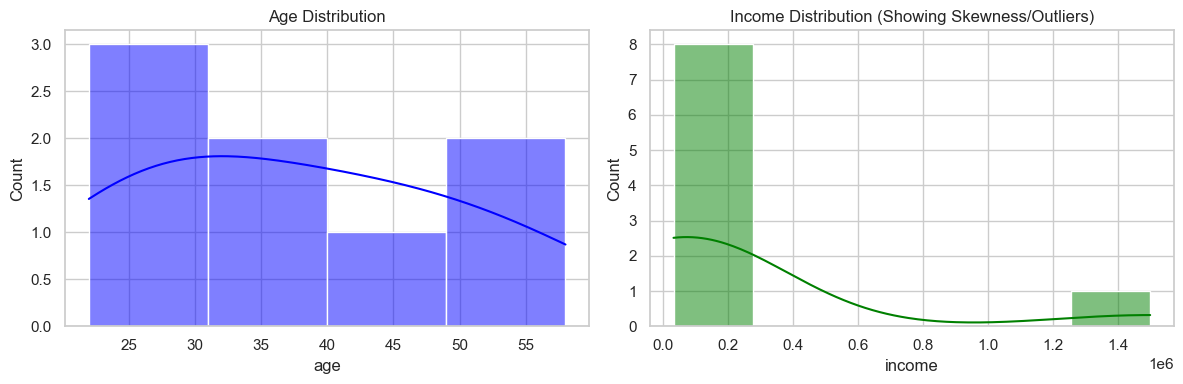

C:\Users\91635\AppData\Local\Temp\ipykernel_14076\3531111378.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='purchased', y='income', data=df_final, palette='Set2')


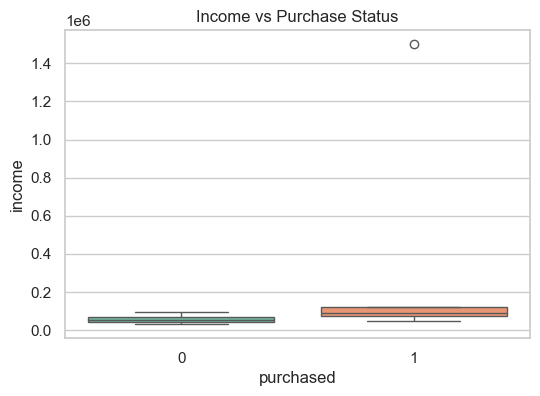

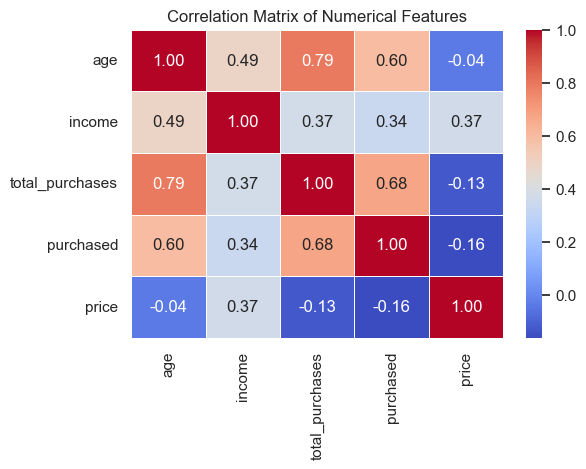

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style for plots
sns.set_theme(style="whitegrid")

# 1. Univariate Analysis: Histograms for numerical columns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df_final['age'].dropna(), kde=True, ax=axes[0], color='blue')
axes[0].set_title('Age Distribution')

sns.histplot(df_final['income'].dropna(), kde=True, ax=axes[1], color='green')
axes[1].set_title('Income Distribution (Showing Skewness/Outliers)')
plt.tight_layout()
plt.show()

# 2. Bivariate Analysis: Income vs Purchased
plt.figure(figsize=(6, 4))
sns.boxplot(x='purchased', y='income', data=df_final, palette='Set2')
plt.title('Income vs Purchase Status')
plt.show()

# 3. Multivariate Analysis: Correlation Heatmap
plt.figure(figsize=(6, 4))
numeric_cols = df_final.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features')
plt.show()

# Step 4: Handling Missing Data

In [7]:
from sklearn.impute import SimpleImputer, KNNImputer

print("--- Missing Values Before Imputation ---")
print(df_final.isnull().sum())

# 1. Most Frequent Imputation for Categorical Data ('education') -> Added .ravel()
cat_imputer = SimpleImputer(strategy='most_frequent')
df_final['education'] = cat_imputer.fit_transform(df_final[['education']]).ravel()

# 2. Simple Imputer (Median) for Numerical Data ('age') -> Added .ravel()
num_imputer = SimpleImputer(strategy='median')
df_final['age'] = num_imputer.fit_transform(df_final[['age']]).ravel()

# 3. KNN Imputer for 'income' -> Added .ravel()
knn_imputer = KNNImputer(n_neighbors=3)
df_final['income'] = knn_imputer.fit_transform(df_final[['income']]).ravel()

print("\n--- Missing Values After Imputation ---")
print(df_final.isnull().sum())

--- Missing Values Before Imputation ---
customer_id           0
age                   2
income                1
education             1
signup_date           0
product_id            0
total_purchases       0
last_purchase_date    3
purchased             0
category              0
price                 0
dtype: int64

--- Missing Values After Imputation ---
customer_id           0
age                   0
income                0
education             0
signup_date           0
product_id            0
total_purchases       0
last_purchase_date    3
purchased             0
category              0
price                 0
dtype: int64


# Step 5: Outlier Detection & Handling

In [8]:
import numpy as np

print("--- Income Summary Before Outlier Handling ---")
print(df_final['income'].describe())

# 1. IQR Method for Outlier Detection
Q1 = df_final['income'].quantile(0.25)
Q3 = df_final['income'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = df_final[(df_final['income'] < lower_bound) | (df_final['income'] > upper_bound)]
print(f"\nNumber of outliers detected using IQR: {len(outliers_iqr)}")

# 2. Winsorization / Percentile Capping (Capping extreme values at 5th and 95th percentiles)
lower_cap = df_final['income'].quantile(0.05)
upper_cap = df_final['income'].quantile(0.95)

df_final['income'] = np.clip(df_final['income'], lower_cap, upper_cap)

print("\n--- Income Summary After Winsorization / Outlier Capping ---")
print(df_final['income'].describe())

--- Income Summary Before Outlier Handling ---
count    1.000000e+01
mean     2.300000e+05
std      4.497505e+05
min      3.100000e+04
25%      5.300000e+04
50%      8.200000e+04
75%      1.137500e+05
max      1.500000e+06
Name: income, dtype: float64

Number of outliers detected using IQR: 2

--- Income Summary After Winsorization / Outlier Capping ---
count        10.000000
mean     173615.000000
std      270945.543985
min       38650.000000
25%       53000.000000
50%       82000.000000
75%      113750.000000
max      928500.000000
Name: income, dtype: float64


# Step 6: Handling Mixed & Date/Time Variables

In [10]:
import pandas as pd

# 1. Convert Date Columns to Datetime
df_final['signup_date'] = pd.to_datetime(df_final['signup_date'])
df_final['last_purchase_date'] = pd.to_datetime(df_final['last_purchase_date'])

# 2. Derive New Feature: days_since_signup & days_since_last_purchase
reference_date = pd.to_datetime('2023-11-01')
df_final['days_since_signup'] = (reference_date - df_final['signup_date']).dt.days

df_final['days_since_last_purchase'] = (reference_date - df_final['last_purchase_date']).dt.days

# Fixed ChainedAssignmentError by avoiding inplace=True
df_final['days_since_last_purchase'] = df_final['days_since_last_purchase'].fillna(999)

# 3. Handling Mixed Variables in customer_id (Using raw string r'\d+' to fix escape warning)
df_final['customer_id_num'] = df_final['customer_id'].str.extract(r'(\d+)').astype(int)

print("--- Updated Dataset Sample with Date & Derived Features ---")
print(df_final[['customer_id', 'signup_date', 'days_since_signup', 'days_since_last_purchase']].head())

--- Updated Dataset Sample with Date & Derived Features ---
  customer_id signup_date  days_since_signup  days_since_last_purchase
0    CUST_101  2022-01-15                655                      31.0
1    CUST_102  2021-06-20                864                      17.0
2    CUST_103  2023-03-10                236                     999.0
3    CUST_104  2020-11-05               1091                      73.0
4    CUST_105  2022-08-19                439                     999.0


# Step 7: Encoding Categorical & Numerical Data

In [11]:
import pandas as pd
from sklearn.preprocessing import OrdinalEncoder

# 1. Ordinal Encoding for 'education' (Defining hierarchy)
education_hierarchy = [['High School', 'Bachelor', 'Master', 'PhD']]
ordinal_encoder = OrdinalEncoder(categories=education_hierarchy)
df_final['education_encoded'] = ordinal_encoder.fit_transform(df_final[['education']])

# 2. One-Hot Encoding for 'category' (Product categories)
df_final = pd.get_dummies(df_final, columns=['category'], prefix='cat', drop_first=True)

# 3. Binning Numerical Features (Binning income into custom groups)
income_bins = [0, 50000, 100000, float('inf')]
income_labels = ['Low', 'Medium', 'High']
df_final['income_group'] = pd.cut(df_final['income'], bins=income_bins, labels=income_labels)

print("--- Dataset Sample After Encoding & Binning ---")
print(df_final[['customer_id', 'education', 'education_encoded', 'income', 'income_group']].head())

--- Dataset Sample After Encoding & Binning ---
  customer_id    education  education_encoded    income income_group
0    CUST_101     Bachelor                1.0   50000.0          Low
1    CUST_102       Master                2.0   75000.0       Medium
2    CUST_103  High School                0.0   62000.0       Medium
3    CUST_104     Bachelor                1.0  230000.0         High
4    CUST_105     Bachelor                1.0   38650.0          Low


# Step 8: Feature Scaling

In [12]:
# Step 8: Feature Scaling Pipeline using ColumnTransformer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler

# Define features to scale
num_features_std = ['age']
num_features_minmax = ['total_purchases']
num_features_robust = ['income']

# Set up ColumnTransformer to apply different scaling methods simultaneously
scaler_transformer = ColumnTransformer(
    transformers=[
        ('std', StandardScaler(), num_features_std),
        ('minmax', MinMaxScaler(), num_features_minmax),
        ('robust', RobustScaler(), num_features_robust)
    ],
    remainder='passthrough' # Keeps other columns unscaled for now
)

# Apply transformer on dataframe
scaled_data_array = scaler_transformer.fit_transform(df_final)

print("--- Feature Scaling via ColumnTransformer Completed Successfully ---")
print(f"Shape of scaled array: {scaled_data_array.shape}")

--- Feature Scaling via ColumnTransformer Completed Successfully ---
Shape of scaled array: (10, 17)


# Step 9: Feature Construction & Transformation

In [13]:
import numpy as np
from sklearn.preprocessing import PowerTransformer, FunctionTransformer

# 1. Create Interaction Features
# Purchase velocity: total purchases per day since signup
df_final['purchases_per_day'] = df_final['total_purchases'] / (df_final['days_since_signup'] + 1)

# 2. Log Transformation using FunctionTransformer
log_transformer = FunctionTransformer(np.log1p, validate=True)
df_final['income_log'] = log_transformer.fit_transform(df_final[['income']])

# 3. Power Transformer (Yeo-Johnson handles zero and negative values effectively)
power_transformer = PowerTransformer(method='yeo-johnson')
df_final['total_purchases_transformed'] = power_transformer.fit_transform(df_final[['total_purchases']])

# 4. Binarization: Frequent buyer indicator (1 if total_purchases > 5, else 0)
df_final['frequent_buyer'] = np.where(df_final['total_purchases'] > 5, 1, 0)

print("--- Dataset Sample After Feature Construction & Transformation ---")
print(df_final[['customer_id', 'purchases_per_day', 'income_log', 'frequent_buyer']].head())

--- Dataset Sample After Feature Construction & Transformation ---
  customer_id  purchases_per_day  income_log  frequent_buyer
0    CUST_101           0.007622   10.819798               0
1    CUST_102           0.013873   11.225257               1
2    CUST_103           0.000000   11.034906               0
3    CUST_104           0.001832   12.345839               0
4    CUST_105           0.000000   10.562328               0


# Step 10: Final Output & Summary Report

In this final step, we export our fully cleaned, transformed, and feature-engineered dataset so it is completely ready for Machine Learning model training (Binary Classification).

### Project Summary Report:
1. **Techniques Used:** 
   * Data integration across CSV, JSON, SQLite, and REST API.
   * Missing data imputation using Most Frequent, Median SimpleImputer, and KNNImputer.
   * Outlier detection via IQR and handling via Winsorization (percentile capping).
   * Feature extraction from Date/Time variables (`days_since_signup`, `days_since_last_purchase`).
   * Categorical encoding (Ordinal Encoding, One-Hot Encoding) and Numerical Binning.
   * Feature scaling via ColumnTransformer (StandardScaler, MinMaxScaler, RobustScaler).
   * Advanced feature construction (interaction features, log transforms, PowerTransformer, binarization).

2. **Biggest Issues with Raw Data:**
   * Missing values in demographic (`age`, `income`, `education`) and transaction records.
   * Extreme outlier in income ($1,500,000 distorting the distribution).
   * Unstructured dates stored as strings and mixed alphanumeric customer IDs.
   * Categorical variables and raw scales that ML models cannot interpret directly.

3. **Imputation & Scaling Performance:**
   * **KNNImputer** worked best for numeric features like income because it preserved local data structures by finding nearest neighbor similarities.
   * **RobustScaler** and **Winsorization** proved most effective for handling income features affected by heavy-tailed distributions and outliers.

In [14]:
# Exporting the final processed dataset to CSV
output_filename = 'processed_customer_data.csv'
df_final.to_csv(output_filename, index=False)

print(f"--- Pipeline Completed Successfully! ---")
print(f"Cleaned dataset successfully exported to '{output_filename}'")
print(f"Final dataset shape: {df_final.shape}")
print("\nFirst 3 rows of processed data:")
print(df_final.head(3))

--- Pipeline Completed Successfully! ---
Cleaned dataset successfully exported to 'processed_customer_data.csv'
Final dataset shape: (10, 21)

First 3 rows of processed data:
  customer_id   age   income    education signup_date product_id  \
0    CUST_101  25.0  50000.0     Bachelor  2022-01-15     PROD_A   
1    CUST_102  34.0  75000.0       Master  2021-06-20     PROD_B   
2    CUST_103  36.5  62000.0  High School  2023-03-10     PROD_A   

   total_purchases last_purchase_date  purchased   price  ...  \
0                5         2023-10-01          1  299.99  ...   
1               12         2023-10-15          1   49.99  ...   
2                0                NaT          0  299.99  ...   

   days_since_last_purchase  customer_id_num  education_encoded  \
0                      31.0              101                1.0   
1                      17.0              102                2.0   
2                     999.0              103                0.0   

   cat_Electronics  ca